In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import torch


def load_and_preprocess_data(file_path, nrows=50000):
    
    dataset = pd.read_csv(file_path, nrows=nrows)

    
    columns_to_remove = ['id', 'device_id', 'device_ip']
    dataset = dataset.drop(columns=columns_to_remove, errors='ignore')  # Ignore if the columns don't exist

    
    dataset['hour'] = pd.to_datetime(dataset['hour'], format='%y%m%d%H')
    dataset['hour_of_day'] = dataset['hour'].dt.hour
    dataset['day_of_week'] = dataset['hour'].dt.dayofweek
    dataset.drop(columns=['hour'], errors='ignore', inplace=True)  # Drop 'hour' column

    return dataset


def encode_categorical(dataframe):
    cat_columns = [
        'C1', 'banner_pos', 'site_id', 'site_domain', 'site_category',
        'app_id', 'app_domain', 'app_category', 'device_model',
        'device_type', 'device_conn_type', 'C14', 'C15', 'C16',
        'C17', 'C18', 'C19', 'C20', 'C21'
    ]
    
    
    encoded_data = pd.get_dummies(dataframe, columns=cat_columns, drop_first=True)
    
    return encoded_data


def standardize_features(feature_data):
    scaler = StandardScaler()
    feature_data[['hour_of_day', 'day_of_week']] = scaler.fit_transform(feature_data[['hour_of_day', 'day_of_week']])
    
    
    feature_data = feature_data.astype({col: 'int32' for col in feature_data.select_dtypes(include=['bool']).columns})
    
    return feature_data


def create_tensors(features, labels):
    features_tensor = torch.tensor(features.values, dtype=torch.float32)
    labels_tensor = torch.tensor(labels.values, dtype=torch.float32)
    
    return features_tensor, labels_tensor


def main(file_path):
    
    data = load_and_preprocess_data(file_path)

    
    data = encode_categorical(data)
    
    
    features = data.drop(columns=['click'])
    target = data['click']
    
    
    features = standardize_features(features)
    
    
    features_tensor, target_tensor = create_tensors(features, target)

    
    print(f'Features tensor shape: {features_tensor.shape}, Target tensor shape: {target_tensor.shape}')


if __name__ == "__main__":
    file_path = 'C:/Users/SHREYANSH/Downloads/train.csv'
    main(file_path)


Features tensor shape: torch.Size([50000, 4710]), Target tensor shape: torch.Size([50000])


Features tensor shape: torch.Size([50000, 4710]), Target tensor shape: torch.Size([50000])


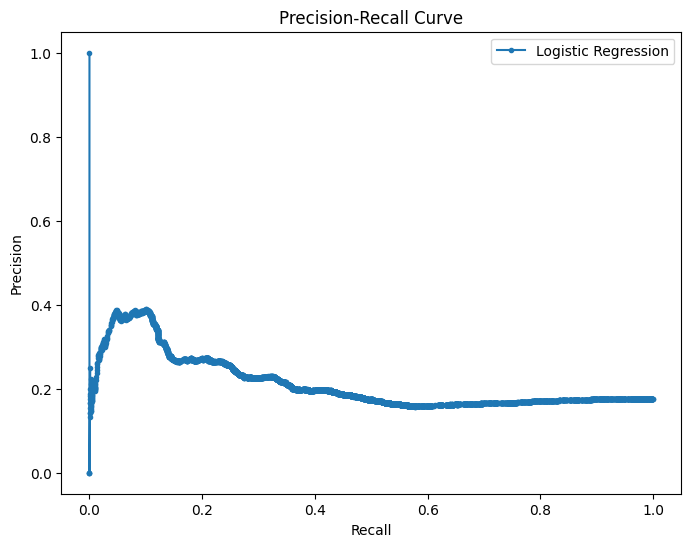

In [5]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve

# Function to load and preprocess data
def load_and_preprocess_data(file_path, nrows=50000):
    # Read the dataset
    dataset = pd.read_csv(file_path, nrows=nrows)

    # Remove irrelevant columns
    columns_to_remove = ['id', 'device_id', 'device_ip']
    dataset = dataset.drop(columns=columns_to_remove, errors='ignore')  # Ignore if the columns don't exist

    # Convert 'hour' column to datetime and derive new features
    dataset['hour'] = pd.to_datetime(dataset['hour'], format='%y%m%d%H')
    dataset['hour_of_day'] = dataset['hour'].dt.hour
    dataset['day_of_week'] = dataset['hour'].dt.dayofweek
    dataset.drop(columns=['hour'], errors='ignore', inplace=True)  # Drop 'hour' column

    return dataset

# Function for one-hot encoding of categorical features
def encode_categorical(dataframe):
    categorical_cols = [
        'C1', 'banner_pos', 'site_id', 'site_domain', 'site_category',
        'app_id', 'app_domain', 'app_category', 'device_model',
        'device_type', 'device_conn_type', 'C14', 'C15', 'C16',
        'C17', 'C18', 'C19', 'C20', 'C21'
    ]
    
    # Apply one-hot encoding
    encoded_data = pd.get_dummies(dataframe, columns=categorical_cols, drop_first=True)
    
    return encoded_data

# Function to standardize feature columns
def standardize_features(feature_data):
    scaler = StandardScaler()
    feature_data[['hour_of_day', 'day_of_week']] = scaler.fit_transform(feature_data[['hour_of_day', 'day_of_week']])
    
    # Change boolean columns to int32
    feature_data = feature_data.astype({col: 'int32' for col in feature_data.select_dtypes(include=['bool']).columns})
    
    return feature_data

# Function to convert data into PyTorch tensors
def create_tensors(features, labels):
    features_tensor = torch.tensor(features.values, dtype=torch.float32)
    labels_tensor = torch.tensor(labels.values, dtype=torch.float32)
    
    return features_tensor, labels_tensor

# Logistic Regression Model
class LogisticRegressionModel(nn.Module):
    def __init__(self, input_dim):
        super(LogisticRegressionModel, self).__init__()
        self.linear_layer = nn.Linear(input_dim, 1)  # Output for binary classification

    def forward(self, inputs):
        return torch.sigmoid(self.linear_layer(inputs))

# Train the logistic regression model
def train_model(features, targets, num_epochs=100, learning_rate=0.01):
    # Split the data into training and testing sets
    train_features, test_features, train_targets, test_targets = train_test_split(features, targets, test_size=0.2, random_state=42)

    # Model, loss function, and optimizer initialization
    input_dimension = train_features.shape[1]
    logistic_model = LogisticRegressionModel(input_dimension)
    loss_function = nn.BCELoss()  # Binary Cross Entropy Loss
    optimizer = optim.SGD(logistic_model.parameters(), lr=learning_rate)

    # Training loop
    for epoch in range(num_epochs):
        logistic_model.train()

        # Forward pass
        predictions = logistic_model(train_features).squeeze()  # Predictions
        loss_value = loss_function(predictions, train_targets.float())  # Calculate loss

        # Backward pass and optimization
        optimizer.zero_grad()
        loss_value.backward()
        optimizer.step()

    return logistic_model, test_features, test_targets

# Evaluate the model
def evaluate_model(model, test_features, test_targets):
    model.eval()
    with torch.no_grad():
        predicted_scores = model(test_features).squeeze()

    # Calculate precision and recall
    precision_scores, recall_scores, thresholds = precision_recall_curve(test_targets, predicted_scores)

    return precision_scores, recall_scores

# Plot precision-recall curve
def plot_precision_recall_curve(precision_scores, recall_scores):
    plt.figure(figsize=(8, 6))
    plt.plot(recall_scores, precision_scores, marker='.', label='Logistic Regression')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend()
    plt.show()

# Main function to run the preprocessing pipeline and training
def main(file_path):
    # Load and preprocess the data
    data = load_and_preprocess_data(file_path)

    # Encode categorical features
    data = encode_categorical(data)
    
    # Split features and labels
    features = data.drop(columns=['click'])
    target = data['click']
    
    # Scale features
    features = standardize_features(features)
    
    # Convert to tensors
    features_tensor, target_tensor = create_tensors(features, target)

    # Print shapes of tensors
    print(f'Features tensor shape: {features_tensor.shape}, Target tensor shape: {target_tensor.shape}')

    # Train the logistic regression model
    logistic_model, test_features, test_targets = train_model(features_tensor, target_tensor)

    # Evaluate the model
    precision_scores, recall_scores = evaluate_model(logistic_model, test_features, test_targets)

    # Plot the precision-recall curve
    plot_precision_recall_curve(precision_scores, recall_scores)

# Execute the main function
if __name__ == "__main__":
    file_path = 'C:/Users/SHREYANSH/Downloads/train.csv'
    main(file_path)
